# 🏢 Mini Project: Prediksi Gaji Karyawan — PT Data Sicentis
### Studi Kasus Hari ke-2: Anda sebagai Data Scientist

**Latar Belakang Kasus:**
Anda baru saja direkrut sebagai Data Scientist di **PT Data**. Divisi HR meminta Anda membangun model **Machine Learning Regresi** untuk memprediksi **Gaji (Salary)** karyawan berdasarkan atributnya: Usia, Gender, Tingkat Pendidikan, Jabatan/Job Title, dan Lama Pengalaman Kerja.

**Tugas Anda sebagai Data Scientist:**
1. Melakukan eksplorasi & pembersihan data (EDA & Data Cleaning)
2. Melakukan encoding pada fitur kategorikal (termasuk *Job Title* menggunakan **One-Hot Encoding/OHE**)
3. **Memilih sendiri** algoritma regresi terbaik dari beberapa pilihan yang tersedia (boleh coba lebih dari 1, boleh dibandingkan)
4. Mengevaluasi performa model secara lengkap
5. Menggunakan model untuk **memprediksi gaji karyawan baru**

Selamat mengerjakan, Bapak/Ibu Data Scientist PT Data! 🚀


## 1️⃣ Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

# ==== 7 Algoritma Regresi yang tersedia untuk dipilih ====
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

# Evaluasi
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                              r2_score, mean_absolute_percentage_error)

import joblib

sns.set_style("whitegrid")
print("✅ Semua library berhasil diimport.")

✅ Semua library berhasil diimport.


## 2️⃣ Load Data
Dataset yang digunakan: `Salary_Data.csv` (fitur: Age, Gender, Education Level, Job Title, Years of Experience, Salary).

In [2]:
df = pd.read_csv("/content/Salary Data.csv")
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (375, 6)


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


## 3️⃣ Exploratory Data Analysis (EDA)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  373 non-null    float64
 1   Gender               373 non-null    object 
 2   Education Level      373 non-null    object 
 3   Job Title            373 non-null    object 
 4   Years of Experience  373 non-null    float64
 5   Salary               373 non-null    float64
dtypes: float64(3), object(3)
memory usage: 17.7+ KB


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,373.0,NaN,NaN,NaN,37.431635,7.069073,23.0,31.0,36.0,44.0,53.0
Gender,373,2,Male,194,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education Level,373,3,Bachelor's,224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job Title,373,174,Director of Marketing,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Years of Experience,373.0,NaN,NaN,NaN,10.030831,6.557007,0.0,4.0,9.0,15.0,25.0
Salary,373.0,NaN,NaN,NaN,100577.345845,48240.013482,350.0,55000.0,95000.0,140000.0,250000.0


In [5]:
print("Jumlah missing value per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())
print("\nJumlah Job Title unik:", df['Job Title'].nunique())
print("Kategori Gender:", df['Gender'].dropna().unique())
print("Kategori Education Level:", df['Education Level'].dropna().unique())

Jumlah missing value per kolom:
Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

Jumlah baris duplikat: 50

Jumlah Job Title unik: 174
Kategori Gender: ['Male' 'Female']
Kategori Education Level: ["Bachelor's" "Master's" 'PhD']


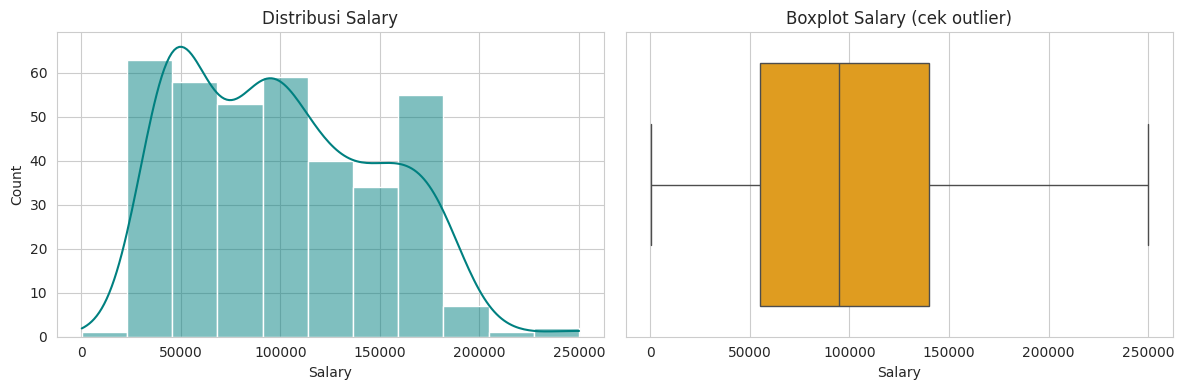

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Salary'], kde=True, ax=axes[0], color='teal')
axes[0].set_title("Distribusi Salary")
sns.boxplot(x=df['Salary'], ax=axes[1], color='orange')
axes[1].set_title("Boxplot Salary (cek outlier)")
plt.tight_layout()
plt.show()

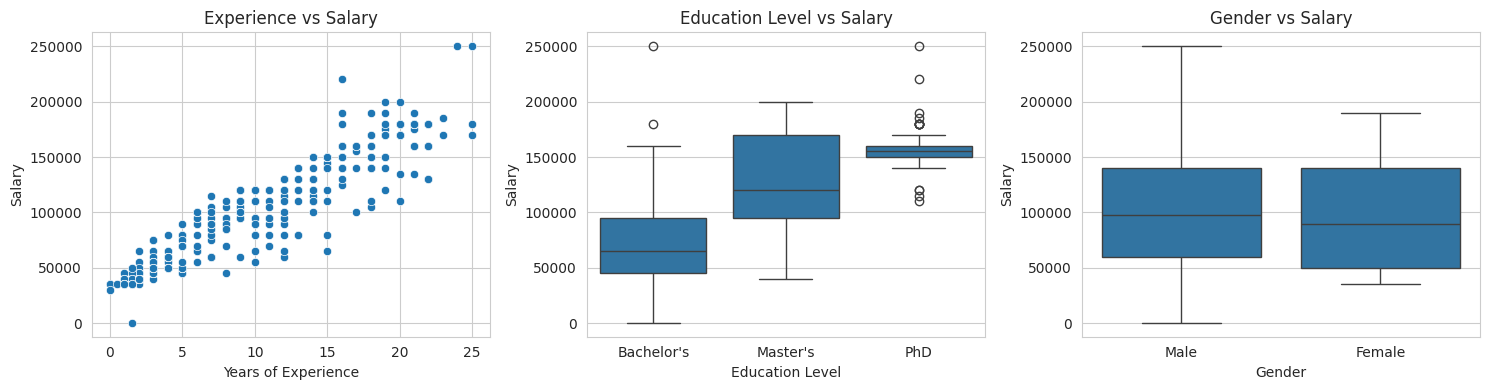

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.scatterplot(data=df, x='Years of Experience', y='Salary', ax=axes[0])
axes[0].set_title("Experience vs Salary")
sns.boxplot(data=df, x='Education Level', y='Salary', ax=axes[1])
axes[1].set_title("Education Level vs Salary")
sns.boxplot(data=df, x='Gender', y='Salary', ax=axes[2])
axes[2].set_title("Gender vs Salary")
plt.tight_layout()
plt.show()

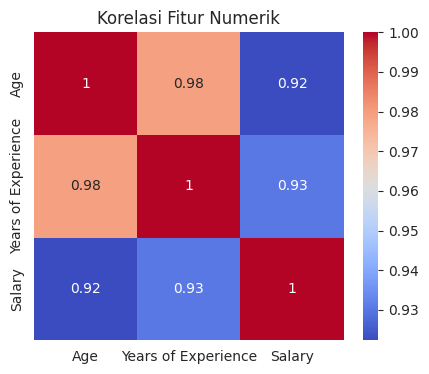

In [8]:
plt.figure(figsize=(5,4))
sns.heatmap(df[['Age','Years of Experience','Salary']].corr(), annot=True, cmap='coolwarm')
plt.title("Korelasi Fitur Numerik")
plt.show()

**📌 Insight dari EDA:**
- Ditemukan **baris kosong (missing value total)** yang perlu dihapus.
- Ditemukan **outlier** pada kolom `Salary` (nilai sangat kecil, kemungkinan salah input, misalnya nilai 350) yang tidak wajar dibandingkan gaji lain di kisaran serupa.
- `Years of Experience` berkorelasi kuat positif terhadap `Salary` → wajar secara bisnis.
- `Job Title` memiliki kategori yang sangat banyak (ratusan) sehingga akan di-encode dengan **One-Hot Encoding (OHE)**.

## 4️⃣ Data Cleaning

In [9]:
print("Sebelum cleaning:", df.shape)

# 1. Hapus baris yang seluruh kolomnya kosong / mengandung missing value
df = df.dropna().reset_index(drop=True)

# 2. Hapus outlier gaji yang tidak wajar (misalnya salah input, gaji < Rp 1.000)
df = df[df['Salary'] > 1000].reset_index(drop=True)

print("Setelah cleaning :", df.shape)
df.describe()

Sebelum cleaning: (375, 6)
Setelah cleaning : (372, 6)


,Age,Years of Experience,Salary
count,372.000000,372.000000,372.000000
mean,37.454301,10.053763,100846.774194
std,7.065009,6.550843,48023.137565
min,23.000000,0.000000,30000.000000
25%,31.750000,4.000000,55000.000000
50%,36.000000,9.000000,95000.000000
75%,44.000000,15.000000,140000.000000
max,53.000000,25.000000,250000.000000


In [10]:
df

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
...,...,...,...,...,...,...
367,35.0,Female,Bachelor's,Senior Marketing Analyst,8.0,85000.0
368,43.0,Male,Master's,Director of Operations,19.0,170000.0
369,29.0,Female,Bachelor's,Junior Project Manager,2.0,40000.0
370,34.0,Male,Bachelor's,Senior Operations Coordinator,7.0,90000.0


## 5️⃣ Feature Engineering & Encoding
Fitur yang digunakan **semuanya** (Age, Gender, Education Level, Job Title, Years of Experience).

- `Age`, `Years of Experience` → **StandardScaler** (numerik)
- `Gender`, `Education Level`, `Job Title` → **One-Hot Encoding (OHE)**

> `handle_unknown='ignore'` dipakai supaya saat prediksi data baru dengan Job Title yang belum pernah ada di data training, model tetap bisa jalan (tidak error).

In [11]:
X = df[['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience']]
y = df['Salary']

numeric_features = ['Age', 'Years of Experience']
categorical_features = ['Gender', 'Education Level', 'Job Title']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

print("Fitur numerik    :", numeric_features)
print("Fitur kategorikal:", categorical_features, "-> di-encode dengan One-Hot Encoding")

Fitur numerik    : ['Age', 'Years of Experience']
Fitur kategorikal: ['Gender', 'Education Level', 'Job Title'] -> di-encode dengan One-Hot Encoding


## 6️⃣ Split Data Train & Test

In [12]:
train_x, test_x, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=42)
print("Data Train:", train_x.shape)
print("Data Test :", test_x.shape)

Data Train: (297, 5)
Data Test : (75, 5)


In [13]:
train_x

,Age,Gender,Education Level,Job Title,Years of Experience
192,34.0,Male,Bachelor's,Senior Product Manager,7.0
75,37.0,Male,Bachelor's,Project Manager,10.0
84,29.0,Female,Bachelor's,Junior Designer,2.0
360,33.0,Male,Bachelor's,Junior Marketing Specialist,5.0
16,33.0,Female,Master's,Marketing Manager,7.0
...,...,...,...,...,...
71,39.0,Female,Bachelor's,Recruiter,11.0
106,30.0,Female,Bachelor's,Digital Content Producer,3.0
270,47.0,Female,Master's,Director of Marketing,20.0
348,31.0,Male,Bachelor's,Junior Marketing Coordinator,3.0


## 7️⃣ Daftar Algoritma Regresi yang Tersedia
Sebagai Data Scientist di PT Data, silakan **pilih sendiri** algoritma mana yang menurut Anda paling cocok. Anda boleh memilih **maksimal 2 algoritma yang menurut anda bagus** algoritma nanti bisa untuk dibandingkan performanya

| No | Algoritma |
|----|-----------|
| 1  | Linear Regression |
| 2  | Ridge Regression |
| 3  | Lasso Regression |
| 4  | Decision Tree Regressor |
| 5  | Random Forest Regressor |
| 6  | Gradient Boosting Regressor |
| 7  | K-Nearest Neighbors (KNN) Regressor |


In [14]:
# Semua algoritma sudah didefinisikan / di-import di awal (Cell Import Library).
# Dictionary berikut memetakan nomor pilihan -> (nama algoritma, objek model)

models_available = {
    '1': ('Linear Regression', LinearRegression()),
    '2': ('Ridge Regression', Ridge(alpha=1.0)),
    '3': ('Lasso Regression', Lasso(alpha=100)),
    '4': ('Decision Tree Regressor', DecisionTreeRegressor(max_depth=6, random_state=42)),
    '5': ('Random Forest Regressor', RandomForestRegressor(n_estimators=200, random_state=42)),
    '6': ('Gradient Boosting Regressor', GradientBoostingRegressor(random_state=42)),
    '7': ('K-Nearest Neighbors Regressor', KNeighborsRegressor(n_neighbors=5)),
}

print("Daftar algoritma yang tersedia:")
for k, (nama, _) in models_available.items():
    print(f"  {k}. {nama}")

Daftar algoritma yang tersedia:
  1. Linear Regression
  2. Ridge Regression
  3. Lasso Regression
  4. Decision Tree Regressor
  5. Random Forest Regressor
  6. Gradient Boosting Regressor
  7. K-Nearest Neighbors Regressor


## 8️⃣ Input Pilihan Algoritma (INTERAKTIF)
Jalankan cell di bawah ini, lalu **ketik pilihan Anda** pada kotak input yang muncul. **Maksimal 2 algoritma, silahkan bapak ibu bisa masukkan 2 angka**

Contoh input yang valid:
- `1` → hanya Linear Regression
- `1,5` → Linear Regression, Random Forest

In [18]:
pilihan = input("Masukkan maksimal 2 nomor algoritma (pisahkan dengan koma, contoh: 1,3): ")
pilihan = pilihan.strip()

# Ambil pilihan yang valid dan hilangkan duplikat
selected_keys = []
for k in pilihan.split(','):
    k = k.strip()
    if k in models_available and k not in selected_keys:
        selected_keys.append(k)

# Validasi
if len(selected_keys) == 0:
    print("⚠️ Tidak ada pilihan yang valid. Silakan jalankan ulang program.")
    exit()

if len(selected_keys) > 2:
    print("⚠️ Maksimal hanya boleh memilih 2 algoritma.")
    exit()

print("\n✅ Algoritma yang akan dijalankan:")
for k in selected_keys:
    print(f"- {models_available[k][0]}")

Masukkan maksimal 2 nomor algoritma (pisahkan dengan koma, contoh: 1,3): 1,6

✅ Algoritma yang akan dijalankan:
- Linear Regression
- Gradient Boosting Regressor


## 9️⃣ Training Model

In [19]:
trained_models = {}   # menyimpan pipeline (preprocessing + model) yang sudah di-fit

for key in selected_keys:
    nama_model, model = models_available[key]
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipeline.fit(train_x, train_y)
    trained_models[key] = {'name': nama_model, 'pipeline': pipeline}
    print(f"✅ {nama_model} selesai dilatih.")

✅ Linear Regression selesai dilatih.
✅ Gradient Boosting Regressor selesai dilatih.


## 🔟 Evaluasi Model (Lengkap)
Metrik evaluasi regresi yang digunakan:
- **MAE**  (Mean Absolute Error)
- **MSE**  (Mean Squared Error)
- **RMSE** (Root Mean Squared Error)
- **MAPE** (Mean Absolute Percentage Error)
- **R²**   (Koefisien Determinasi)
- **Adjusted R²**

In [20]:
def evaluasi_model(y_true, y_pred, n_features):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    r2   = r2_score(y_true, y_pred)
    n    = len(y_true)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse,
            'MAPE (%)': mape, 'R2': r2, 'Adjusted R2': adj_r2}

hasil_evaluasi = []
n_features = train_x.shape[1]

for key in selected_keys:
    nama_model = trained_models[key]['name']
    pipeline   = trained_models[key]['pipeline']
    y_pred     = pipeline.predict(test_x)

    metrik = evaluasi_model(test_y, y_pred, n_features)
    metrik['Model'] = nama_model
    hasil_evaluasi.append(metrik)

    trained_models[key]['y_pred'] = y_pred

hasil_df = pd.DataFrame(hasil_evaluasi)
hasil_df = hasil_df[['Model', 'MAE', 'MSE', 'RMSE', 'MAPE (%)', 'R2', 'Adjusted R2']]
hasil_df = hasil_df.sort_values(by='R2', ascending=False).reset_index(drop=True)

print("📊 Tabel Perbandingan Evaluasi Model:")
hasil_df

📊 Tabel Perbandingan Evaluasi Model:


,Model,MAE,MSE,RMSE,MAPE (%),R2,Adjusted R2
0,Gradient Boosting Regressor,10126.957090,3.148702e+08,17744.581109,10.364268,0.876329,0.867367
1,Linear Regression,12273.497081,3.801985e+08,19498.679617,15.609666,0.850670,0.839849


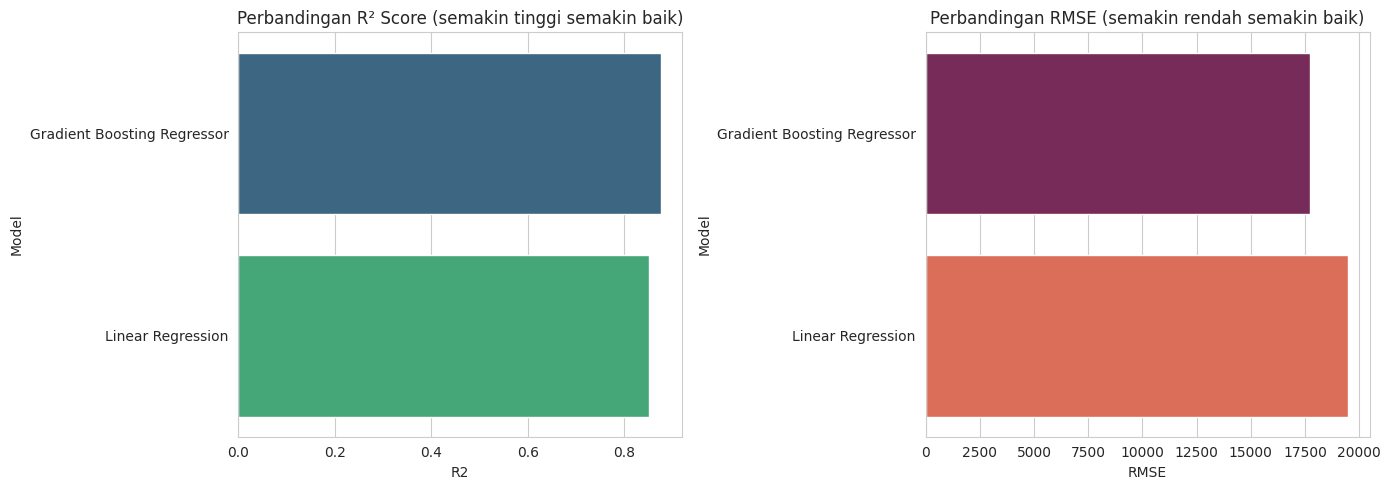


🏆 Model dengan performa terbaik (R² tertinggi) : Gradient Boosting Regressor
   R2  = 0.8763
   RMSE= 17744.58


In [21]:
if len(hasil_df) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=hasil_df, x='R2', y='Model', ax=axes[0], palette='viridis')
    axes[0].set_title("Perbandingan R² Score (semakin tinggi semakin baik)")
    sns.barplot(data=hasil_df, x='RMSE', y='Model', ax=axes[1], palette='rocket')
    axes[1].set_title("Perbandingan RMSE (semakin rendah semakin baik)")
    plt.tight_layout()
    plt.show()
else:
    print("Hanya 1 model dipilih, visual perbandingan dilewati.")

model_terbaik_key = hasil_df.iloc[0]['Model']
best_key = [k for k in selected_keys if trained_models[k]['name'] == model_terbaik_key][0]
print(f"\n🏆 Model dengan performa terbaik (R² tertinggi) : {trained_models[best_key]['name']}")
print(f"   R2  = {hasil_df.iloc[0]['R2']:.4f}")
print(f"   RMSE= {hasil_df.iloc[0]['RMSE']:.2f}")

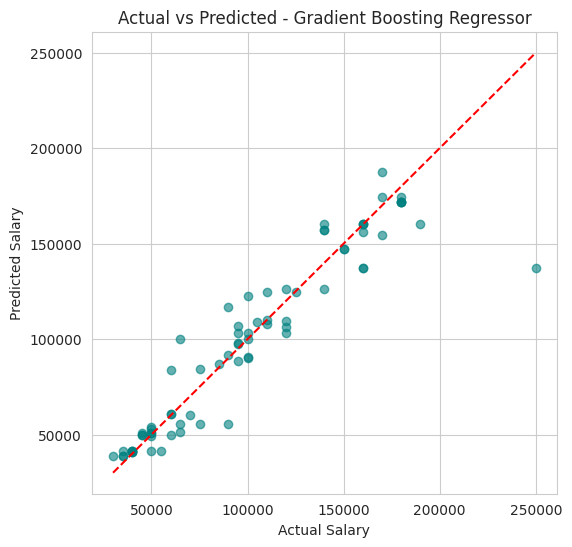

In [22]:
# Visualisasi Actual vs Predicted untuk model terbaik
plt.figure(figsize=(6,6))
plt.scatter(test_y, trained_models[best_key]['y_pred'], alpha=0.6, color='teal')
plt.plot([test_y.min(), test_y.max()], [test_y.min(), test_y.max()], 'r--')
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title(f"Actual vs Predicted - {trained_models[best_key]['name']}")
plt.show()

## 1️⃣1️⃣ Prediksi Data Karyawan Baru (INTERAKTIF)
Sekarang saatnya PT Data menggunakan model Anda! Masukkan data karyawan baru untuk diprediksi gajinya.

Jalankan cell di bawah, lalu isi input satu per satu sesuai permintaan.

In [23]:
print("=== Input Data Karyawan Baru ===")
age_baru    = float(input("Usia (contoh: 30): "))
gender_baru = input("Gender (Male/Female): ").strip()
edu_baru    = input("Education Level (Bachelor's/Master's/PhD): ").strip()
job_baru    = input("Job Title (contoh: Data Scientist): ").strip()
exp_baru    = float(input("Years of Experience (contoh: 5): "))

data_baru = pd.DataFrame({
    'Age': [age_baru],
    'Gender': [gender_baru],
    'Education Level': [edu_baru],
    'Job Title': [job_baru],
    'Years of Experience': [exp_baru]
})

print("\nData karyawan baru yang akan diprediksi:")
data_baru

=== Input Data Karyawan Baru ===
Usia (contoh: 30): 30
Gender (Male/Female): Male
Education Level (Bachelor's/Master's/PhD): Bachelor's
Job Title (contoh: Data Scientist): Data Scientist
Years of Experience (contoh: 5): 3

Data karyawan baru yang akan diprediksi:


,Age,Gender,Education Level,Job Title,Years of Experience
0,30.0,Male,Bachelor's,Data Scientist,3.0


In [24]:
print("=== 💰 Hasil Prediksi Gaji ===\n")
for key in selected_keys:
    nama_model = trained_models[key]['name']
    pred_salary = trained_models[key]['pipeline'].predict(data_baru)[0]
    tanda = "🏆" if key == best_key else "  "
    print(f"{tanda} {nama_model:35s}: {pred_salary:,.0f}")

print(f"\n📌 Rekomendasi PT Data (berdasarkan model terbaik - {trained_models[best_key]['name']}):")
pred_final = trained_models[best_key]['pipeline'].predict(data_baru)[0]
print(f"   Estimasi Gaji: {pred_final:,.0f}")

=== 💰 Hasil Prediksi Gaji ===

   Linear Regression                  : 73,283
🏆 Gradient Boosting Regressor        : 53,676

📌 Rekomendasi PT Data (berdasarkan model terbaik - Gradient Boosting Regressor):
   Estimasi Gaji: 53,676


## 1️⃣2️⃣ (Opsional) Simpan Model Terbaik
Model terbaik dapat disimpan dalam format `.pkl` agar bisa dipakai kembali tanpa training ulang (misalnya untuk dipakai di aplikasi HR PT Data).

In [25]:
nama_file = f"model_{trained_models[best_key]['name'].replace(' ', '_')}.pkl"
joblib.dump(trained_models[best_key]['pipeline'], nama_file)
print(f"✅ Model terbaik berhasil disimpan sebagai: {nama_file}")

✅ Model terbaik berhasil disimpan sebagai: model_Gradient_Boosting_Regressor.pkl


---
### 🎉 Selesai!
Sebagai Data Scientist PT Data, Anda telah:
1. Melakukan EDA & Data Cleaning
2. Melakukan encoding seluruh fitur kategorikal (termasuk Job Title dengan One-Hot Encoding)
3. Memilih & membandingkan algoritma regresi sendiri
4. Mengevaluasi model secara lengkap (MAE, MSE, RMSE, MAPE, R², Adjusted R²)
5. Menggunakan model untuk memprediksi gaji karyawan baru

**Diskusi untuk peserta:** Algoritma mana yang Anda pilih tadi? Mengapa? Apakah hasilnya sesuai ekspektasi Anda sebagai Data Scientist?
